# Section 6 — Numerical Differentiation

[← Least Squares](05_least_squares_best_fit.ipynb) ·
[Module 2](README.md) ·
[Next: Riemann Sums →](07_riemann_sums.ipynb)

Numerical differentiation can be approached in two related ways:

1. replace the derivative limit by a finite difference;
2. interpolate nearby data and differentiate the interpolating polynomial.

### Learning goals

- use forward, backward, and centered differences;
- derive their truncation errors from Taylor's theorem;
- compare first- and second-order formulas;
- differentiate a Newton interpolating polynomial;
- bound derivative error at an interpolation node.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np


## 1. Basic finite differences

### Forward difference

$$
f'(x_0)
\approx
\frac{f(x_0+h)-f(x_0)}{h}.
$$

### Backward difference

$$
f'(x_0)
\approx
\frac{f(x_0)-f(x_0-h)}{h}.
$$

### Centered difference

$$
f'(x_0)
\approx
\frac{f(x_0+h)-f(x_0-h)}{2h}.
$$

Taylor's theorem gives:

- forward/backward error $O(h)$;
- centered error $O(h^2)$.


In [2]:
def f(x):
    return np.log(x)


def forward_difference(function, x_value, h):
    return (
        function(x_value + h)
        - function(x_value)
    ) / h


def backward_difference(function, x_value, h):
    return (
        function(x_value)
        - function(x_value - h)
    ) / h


def centered_difference(function, x_value, h):
    numerator = (
        function(x_value + h)
        - function(x_value - h)
    )
    return numerator / (2.0 * h)


x0 = 1.5
h = 0.01
exact = 1.0 / x0

forward = forward_difference(f, x0, h)
backward = backward_difference(f, x0, h)
centered = centered_difference(f, x0, h)

print(f"exact     = {exact:.10f}")
print(f"forward   = {forward:.10f}")
print(f"backward  = {backward:.10f}")
print(f"centered  = {centered:.10f}")


exact     = 0.6666666667
forward   = 0.6644542719
backward  = 0.6688988151
centered  = 0.6666765435


## 2. Error bounds from Taylor's theorem

For the forward formula,

$$
f'(x_0)
=
\frac{f(x_0+h)-f(x_0)}{h}
-\frac{f''(\xi)}{2}h,
$$

so

$$
|E_F|
\le
\frac{M_2}{2}|h|.
$$

For the centered formula,

$$
f'(x_0)
=
\frac{f(x_0+h)-f(x_0-h)}{2h}
-\frac{f'''(\xi)}{6}h^2,
$$

so

$$
|E_C|
\le
\frac{M_3}{6}h^2.
$$

For $f(x)=\ln x$,

$$
f''(x)=-\frac1{x^2},
\qquad
f'''(x)=\frac2{x^3}.
$$


In [3]:
m2_forward = 1.0 / x0**2
m2_backward = 1.0 / (x0 - h) ** 2
m3_centered = 2.0 / (x0 - h) ** 3

forward_bound = 0.5 * m2_forward * h
backward_bound = 0.5 * m2_backward * h
centered_bound = (m3_centered / 6.0) * h**2

print(f"forward error  = {abs(exact - forward):.3e}")
print(f"forward bound  = {forward_bound:.3e}")
print(f"backward error = {abs(exact - backward):.3e}")
print(f"backward bound = {backward_bound:.3e}")
print(f"centered error = {abs(exact - centered):.3e}")
print(f"centered bound = {centered_bound:.3e}")


forward error  = 2.212e-03
forward bound  = 2.222e-03
backward error = 2.232e-03
backward bound = 2.252e-03
centered error = 9.877e-06
centered bound = 1.008e-05


## 3. Differentiate a Newton interpolating polynomial

The Exam 2 review uses the data

$$
f(4.3)=0,\qquad f(4.8)=0.2,\qquad f(5)=0.2.
$$

Construct

$$
P_2(x)
=
f[x_0]
+
f[x_0,x_1](x-x_0)
+
f[x_0,x_1,x_2](x-x_0)(x-x_1).
$$

Then differentiate the polynomial itself:

$$
P_2'(x)
=
f[x_0,x_1]
+
f[x_0,x_1,x_2]
\left[(x-x_0)+(x-x_1)\right].
$$

At $x=x_0$,

$$
P_2'(x_0)
=
f[x_0,x_1]
+
f[x_0,x_1,x_2](x_0-x_1).
$$


In [4]:
def divided_difference_coefficients(x_nodes, y_nodes):
    """Return Newton divided-difference coefficients."""
    coefficients = np.array(
        y_nodes,
        dtype=float,
    )
    n = len(x_nodes)

    for order in range(1, n):
        for row in range(n - 1, order - 1, -1):
            numerator = (
                coefficients[row]
                - coefficients[row - 1]
            )
            denominator = (
                x_nodes[row]
                - x_nodes[row - order]
            )
            coefficients[row] = (
                numerator / denominator
            )

    return coefficients


x_nodes = np.array([4.3, 4.8, 5.0])
y_nodes = np.array([0.0, 0.2, 0.2])

coefficients = divided_difference_coefficients(
    x_nodes,
    y_nodes,
)

p_prime_x0 = (
    coefficients[1]
    + coefficients[2]
    * (x_nodes[0] - x_nodes[1])
)

print(f"Newton coefficients = {coefficients}")
print(f"P2'(4.3)            = {p_prime_x0:.10f}")


Newton coefficients = [ 0.          0.4        -0.57142857]
P2'(4.3)            = 0.6857142857


### Derivative error at an interpolation node

If $f\in C^3$ and $P_2$ interpolates at $x_0,x_1,x_2$, then at the node $x_0$

$$
f'(x_0)-P_2'(x_0)
=
\frac{f'''(\xi)}{3!}
(x_0-x_1)(x_0-x_2)
$$

for an appropriate $\xi$ in the interval containing the nodes.

If

$$
\max_{[4.3,5]}|f'''(x)|\le10,
$$

then

$$
|f'(4.3)-P_2'(4.3)|
\le
\frac{10}{6}
|(4.3-4.8)(4.3-5)|.
$$


In [5]:
m3 = 10.0
derivative_error_bound = (
    m3
    * abs(
        (x_nodes[0] - x_nodes[1])
        * (x_nodes[0] - x_nodes[2])
    )
    / math.factorial(3)
)

print(
    "derivative error bound = "
    f"{derivative_error_bound:.10f}"
)


derivative error bound = 0.5833333333


## 4. Order experiment

If $E(h)\approx Ch^p$, halving $h$ reduces the error by approximately $2^p$.


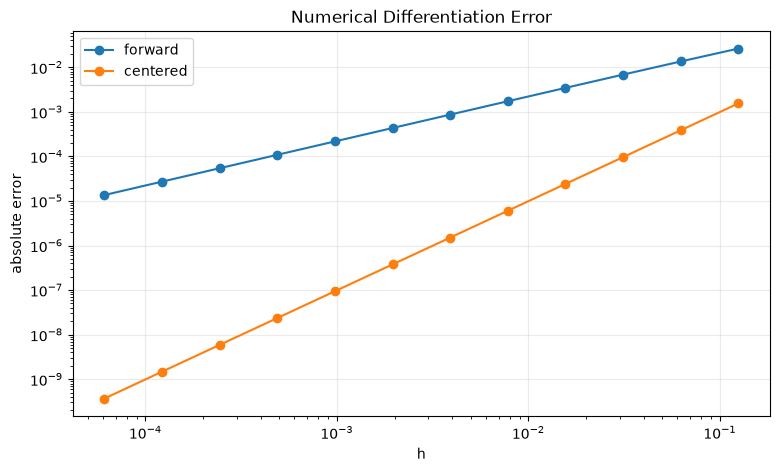

In [6]:
h_values = 2.0 ** (-np.arange(3, 15))
forward_errors = []
centered_errors = []

for step in h_values:
    forward_errors.append(
        abs(
            exact
            - forward_difference(f, x0, step)
        )
    )
    centered_errors.append(
        abs(
            exact
            - centered_difference(f, x0, step)
        )
    )

plt.figure(figsize=(9, 5))
plt.loglog(
    h_values,
    forward_errors,
    "o-",
    label="forward",
)
plt.loglog(
    h_values,
    centered_errors,
    "o-",
    label="centered",
)
plt.xlabel("h")
plt.ylabel("absolute error")
plt.title("Numerical Differentiation Error")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


### References

- Eric Sullivan, *Numerical Methods: An Inquiry-Based Approach with Python*.
- Leon Q. Brin, *Tea Time Numerical Analysis*.
- Richard L. Burden and J. Douglas Faires, *Numerical Analysis*.
- MAD 4401 Exam 2 review.

[Next: Riemann Sums →](07_riemann_sums.ipynb)
